#### 2. Persiapan Environment

In [14]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

#### 3. Membaca Dataset

In [15]:
df = pd.read_csv("data/data.csv")
print(df)

print("Jumlah citation:", len(df))

   Source Target
0      P1    P15
1      P2    P12
2      P3     P8
3      P3    P14
4      P4     P6
5      P5     P1
6      P5     P7
7      P5    P12
8      P6     P1
9      P6     P4
10     P7    P10
11     P8     P4
12     P9     P1
13     P9     P6
14     P9    P10
15     P9    P12
16     P9    P14
17    P10     P8
18    P11     P5
19    P11     P7
20    P11    P12
21    P12     P3
22    P13    P12
23    P14     P5
24    P15     P5
Jumlah citation: 25


#### 4. Membuat Directed Graph

In [20]:
G = nx.from_pandas_edgelist(
    df, source="Source",
    target="Target",
    create_using=nx.DiGraph())
print("Jumlah node :", G.number_of_nodes())
print("Jumlah edge :", G.number_of_edges())

Jumlah node : 15
Jumlah edge : 25


#### 5. Visualisasi Citation Network

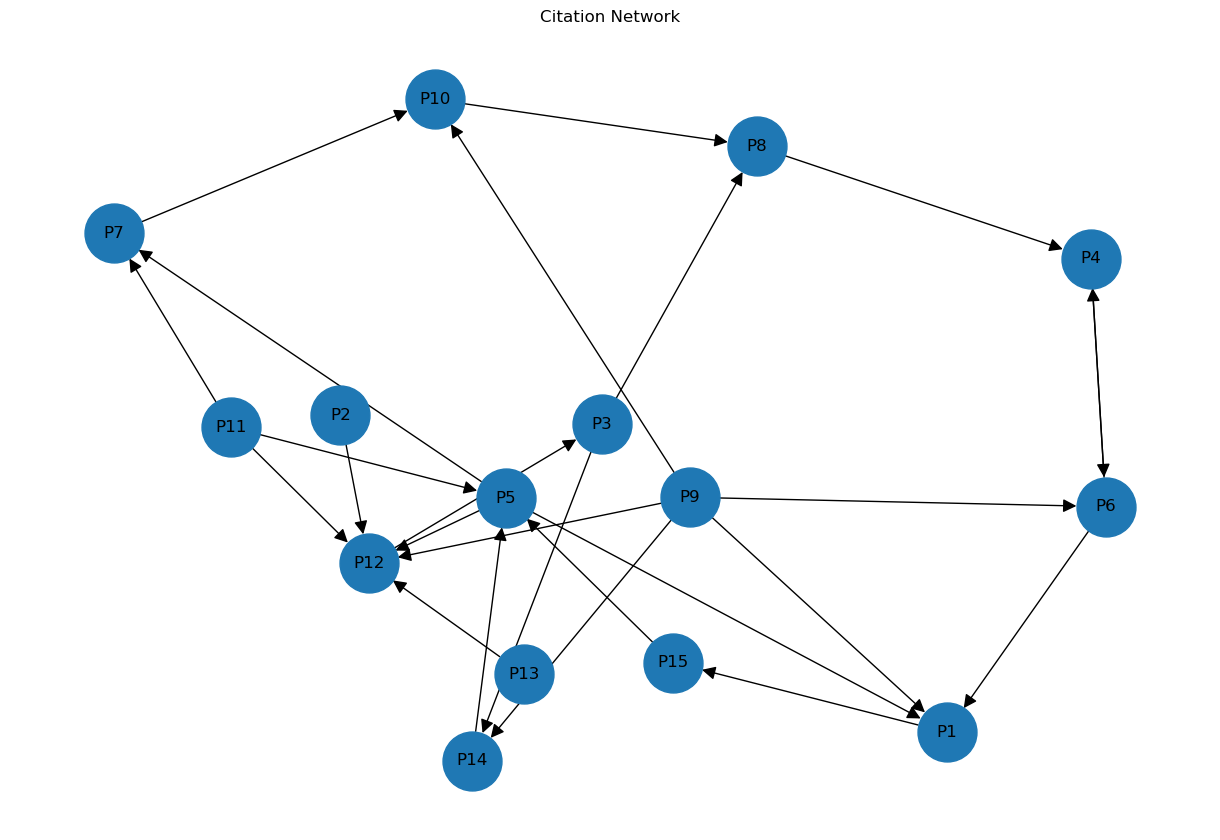

In [19]:
plt.figure(figsize=(12, 8))
pos = nx.spring_layout(
G,
seed=42
)
nx.draw(
G,
pos,
with_labels=True,
node_size=1800,
arrows=True,
arrowsize=20
)
plt.title("Citation Network")
plt.show()

#### 6. Percobaan in degree centrality

In [23]:
in_degree = nx.in_degree_centrality(G)
for node, value in sorted(
in_degree.items(),
key=lambda x: x[1],
reverse=True):
    print(node, round(value, 4))

P12 0.3571
P1 0.2143
P5 0.2143
P8 0.1429
P14 0.1429
P4 0.1429
P6 0.1429
P7 0.1429
P10 0.1429
P15 0.0714
P3 0.0714
P2 0.0
P9 0.0
P11 0.0
P13 0.0


#### 7. Percobaan— Closeness Centrality

In [24]:
closeness = nx.closeness_centrality(G)
for node, value in sorted(
closeness.items(),
key=lambda x: x[1],
reverse=True
):
    print(node, round(value, 4))

P1 0.35
P12 0.3111
P5 0.3111
P8 0.3043
P4 0.3043
P7 0.2745
P15 0.2692
P10 0.2545
P3 0.25
P6 0.2456
P14 0.2154
P2 0.0
P9 0.0
P11 0.0
P13 0.0


#### 8. Percobann — Betweenness Centrality

In [25]:
betweenness = nx.betweenness_centrality(G)
for node, value in sorted(
betweenness.items(),
key=lambda x: x[1],
reverse=True
):
    print(node, round(value, 4))

P5 0.3846
P12 0.2665
P3 0.2445
P1 0.2308
P15 0.2088
P8 0.1923
P4 0.1813
P6 0.1703
P14 0.1264
P7 0.1126
P10 0.1016
P2 0.0
P9 0.0
P11 0.0
P13 0.0


#### 9. Percobann — PageRank

In [26]:
pagerank = nx.pagerank(G)
for node, value in sorted(
pagerank.items(),
key=lambda x: x[1],
reverse=True
):
    print(node, round(value, 4))

P4 0.1363
P5 0.1302
P6 0.1276
P1 0.1028
P15 0.0974
P8 0.0848
P12 0.0684
P3 0.0682
P10 0.054
P7 0.0497
P14 0.0407
P2 0.01
P9 0.01
P11 0.01
P13 0.01


#### 10. Membuat Tabel Perbandingan

In [27]:
result = pd.DataFrame({
"Paper": list(G.nodes()),
"InDegree": [
in_degree[n] for n in G.nodes()
],
"Closeness": [
closeness[n] for n in G.nodes()
],
"Betweenness": [
betweenness[n] for n in G.nodes()
],
"PageRank": [
pagerank[n] for n in G.nodes()
]
})
result = result.round(4)
print(result)

   Paper  InDegree  Closeness  Betweenness  PageRank
0     P1    0.2143     0.3500       0.2308    0.1028
1    P15    0.0714     0.2692       0.2088    0.0974
2     P2    0.0000     0.0000       0.0000    0.0100
3    P12    0.3571     0.3111       0.2665    0.0684
4     P3    0.0714     0.2500       0.2445    0.0682
5     P8    0.1429     0.3043       0.1923    0.0848
6    P14    0.1429     0.2154       0.1264    0.0407
7     P4    0.1429     0.3043       0.1813    0.1363
8     P6    0.1429     0.2456       0.1703    0.1276
9     P5    0.2143     0.3111       0.3846    0.1302
10    P7    0.1429     0.2745       0.1126    0.0497
11   P10    0.1429     0.2545       0.1016    0.0540
12    P9    0.0000     0.0000       0.0000    0.0100
13   P11    0.0000     0.0000       0.0000    0.0100
14   P13    0.0000     0.0000       0.0000    0.0100


#### 11. Menentukan Top Paper Otomatis

Highest In-Degree: P12
Highest Closeness: P1
Highest Betweenness: P5
Highest PageRank: P4


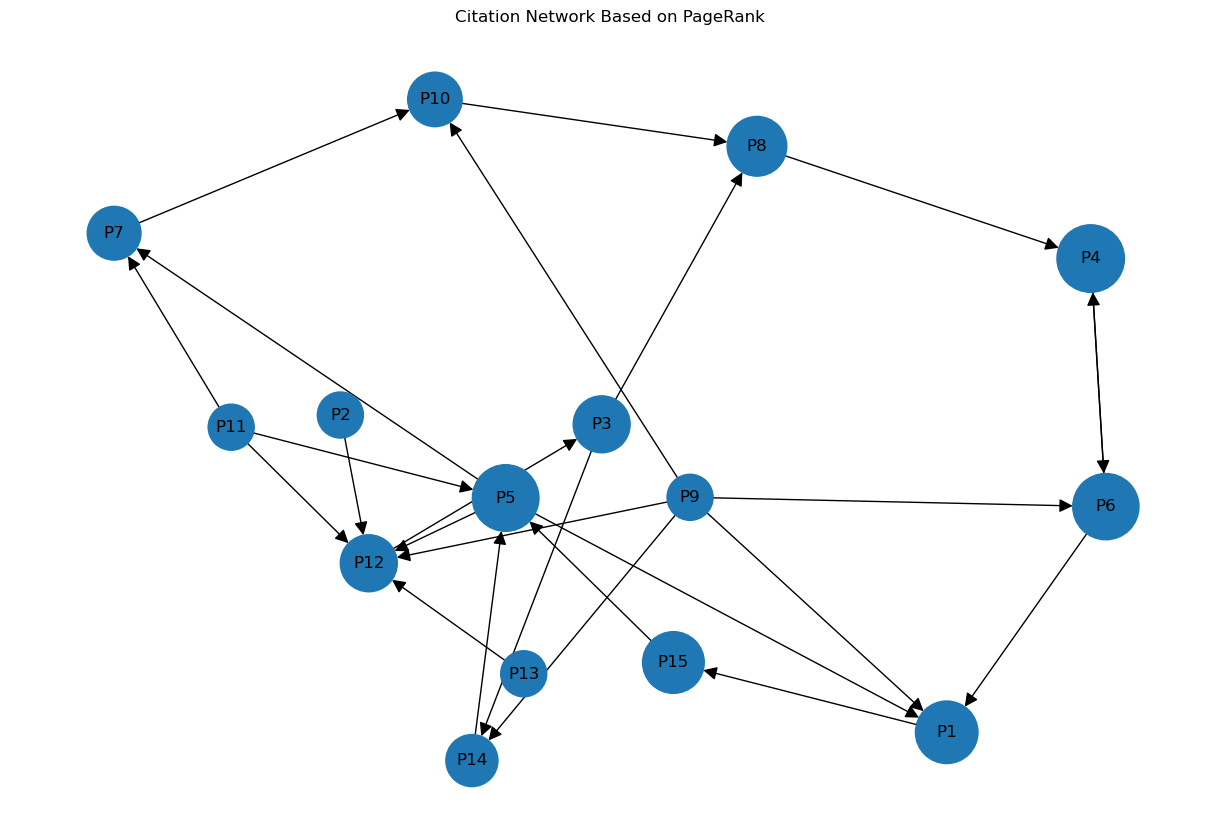

In [28]:
print("Highest In-Degree:", max(in_degree, key=in_degree.get))
print("Highest Closeness:", max(closeness, key=closeness.get))
print("Highest Betweenness:", max(betweenness, key=betweenness.get))
print("Highest PageRank:", max(pagerank, key=pagerank.get))
node_size = [
 1000 + pagerank[n] * 10000
for n in G.nodes()
]
plt.figure(figsize=(12, 8))
nx.draw(
G,
pos,
with_labels=True,
node_size=node_size,
arrows=True,
arrowsize=20)
plt.title("Citation Network Based on PageRank")
plt.show()